# Simulation with shocks and deterministic choice


In [9]:
import sys
sys.path.append("/Users/sofiacattaneo/tesi-inequality/src")

print(sys.path)

['/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python311.zip', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/lib-dynload', '', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/site-packages', '/Users/sofiacattaneo/tesi-inequality/src', '/Users/sofiacattaneo/tesi-inequality/src', '/Users/sofiacattaneo/tesi-inequality/src']


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import parameters as _par
from conditions import *


from functions import *
from distributions import *
from simulations_shock import *
from dynamics import *


#### Fine tuning dei parametri s.t. f_l(x^F)< x^F e che a_R sia sempre >1 => n^p_fin= 1

In [11]:
# ── parametri ──────────────────────────────────────────────────────────────
kw = dict(
    A_p_bar  = _par.A_p_bar,
    A_up_bar = _par.A_up_bar,
    mu       = _par.mu,
    r        = _par.r,
    alpha    = _par.alpha,
    xF       = _par.xF,
    Ybar     = _par.Ybar,
    p        = 0.5,
    gamma_p  = 0.5,
    gamma_up = 0.8,
    F       =1,
    q       =0.5,
)

# ── 1. stampa diagnostica ──────────────────────────────────────────────────   
print_regime_summary(**kw)

╔══ PARAMETRI CORRENTI ══╗
  p = 0.5   q = 0.5   gamma_p = 0.5   gamma_up = 0.8
  A_p_bar = 1.7   A_up_bar = 1.2   xF (F) = 0.3333333333333333


╔══ ANALISI TEORICA (valori attesi) ══╗
  n* calcolato con E[A_p] = A_p_bar*(1-p*gamma_p)*(1+n_p)
───────────────────────────────────────────────────────
 MODE: EXPECTED
───────────────────────────────────────────────────────
  Tipo ramo sinistro : poor_attractor
  Tipo ramo destro : phase_transition
  n*               = 0.2751  (in [0,1] )
  a_R(n_p = 0)     = 0.6317
  a_R(n_p = n*)    = 1.0000
  a_R(n_p = 1)     = 1.9705
  Regime n_p < n*  : poor_and_rich_attractor
  Regime n_p > n*  : poor_attractor_and_explosion

╔══ ANALISI SIMULATIVA (produttività reale) ══╗
  n* calcolato con la produttività effettiva.
  Ad ogni step la simulazione si trova in uno
  dei due casi seguenti con prob (1-p) e p.

───────────────────────────────────────────────────────
 MODE: NOSHOCK
───────────────────────────────────────────────────────
  Tipo ramo sinistro

In [ ]:
T=500
yhigh=0.44
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_shock(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
meanwealth= np.mean(history[T])

print('mean final wealth =', meanwealth)
print('n_p_final=', n_p)

SyntaxError: invalid syntax (710854603.py, line 6)

mean wealth at t= 0 :	 0.22078926225545265
mean wealth at t= 1 :	 0.30382845496425054
mean wealth at t= 52 :	 2550903.2145187794
mean wealth at t= 200 :	 1.0432591979936722e+53
mean wealth at t= 350 :	 1.1071116855234595e+96
mean wealth at t= 500 :	 2.9494852096745062e+141


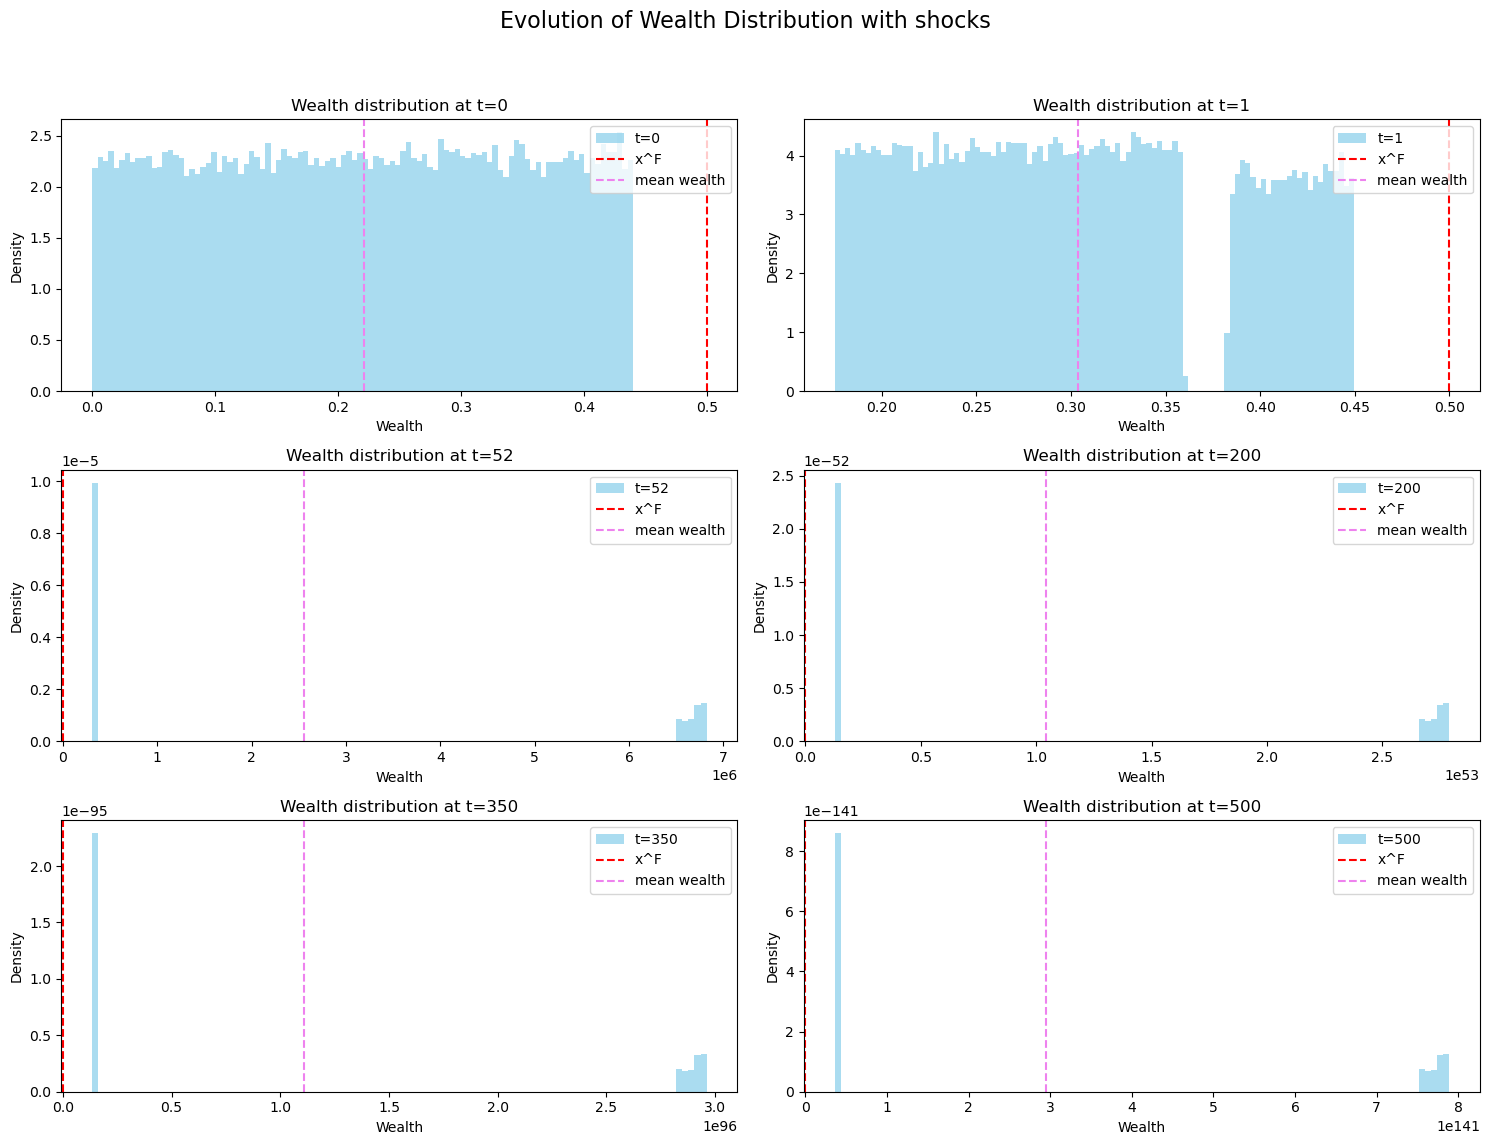

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 52, 200, 350, 500]):
    t = t_val
    ax = axes[i]
    mean=np.mean(history[t])
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    ax.axvline(xF, color='red', linestyle='--', label="x^F")
    #ax.axvline(xp(mu, r, alpha, A_up_bar, Ybar), color='blue', linestyle='--', label="x^P")
    ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', mean)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with shocks', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

#### Fine tuning dei parametri s.t. a_L senza shock sia sotto la bisettrice in x^F e che a_R(1) >1, aR(0)<1 e con shock tutto sotto => n^p_fin=1

In [ ]:
p = 0.5
gamma_p = 0.8
gamma_up = 0.9

A_up_bar = 1.1
A_p_bar = 1.3
F=1
xF= F/(1+mu)
n_p=0

print ('Condizione 35 expected ',Primacondizione(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 expected ',Secondacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) expected ',Terzacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) expected ',Quartacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 no shock ',Primacondizionenoshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 no shock ',Secondacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) no shock',Terzacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) no shock ',Quartacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 shock ',Primacondizioneshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 shock ',Secondacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar ))
print ('Condizione 37(np=0) shock',Terzacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) shock ', Quartacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))

Condizione 35 expected  True
Condizione 36 expected  False
Condizione 37(np=0) expected  True
Condizione 47(np=1) expected  True

Condizione 35 no shock  True
Condizione 36 no shock  True
Condizione 37(np=0) no shock True
Condizione 47(np=1) no shock  True

Condizione 35 shock  True
Condizione 36 shock  False
Condizione 37(np=0) shock True
Condizione 47(np=1) shock  False


Distribuzione con n^p_in>0

n_p_initial= 0.93378
mean final wealth = 6.046221805399804e+147
n_p_final= 1.0
mean wealth at t= 0 :	 2.511586302602095
mean wealth at t= 1 :	 7.0484757708547265
mean wealth at t= 4 :	 39.35261793388841
mean wealth at t= 100 :	 3.518649120411699e+29
mean wealth at t= 350 :	 5.697506939971318e+104
mean wealth at t= 500 :	 6.046221805399804e+147


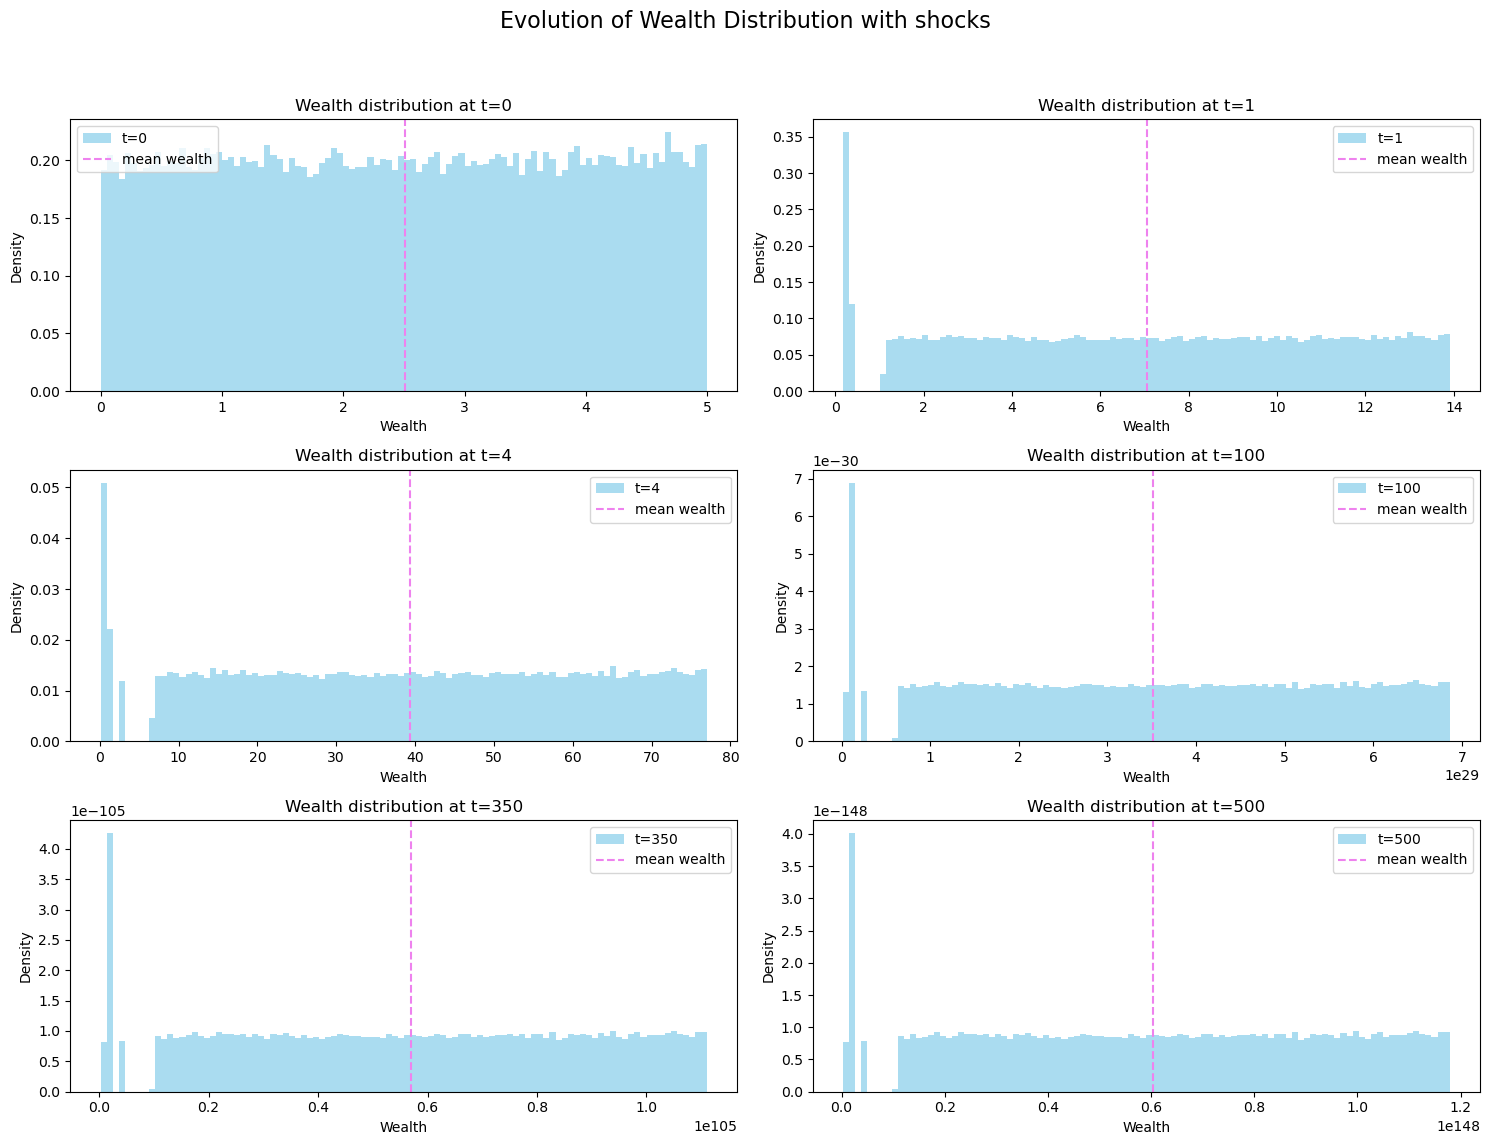

In [ ]:
T=500
yhigh=5
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_shock(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
meanwealth= np.mean(history[T])

print('mean final wealth =', meanwealth)
print('n_p_final=', n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 4, 100, 350, 500]):
    t = t_val
    ax = axes[i]
    mean=np.mean(history[t])
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    #ax.axvline(xF, color='red', linestyle='--', label="x^F")
    #ax.axvline(xp(mu, r, alpha, A_up_bar, Ybar), color='blue', linestyle='--', label="x^P")
    ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', mean)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with shocks', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

Distribuzione con nP_in=0

n_p_initial= 0.0
mean final wealth = 6.318509770567846e+148
n_p_final= 1.0
mean wealth at t= 0 :	 0.1503170600076653
mean wealth at t= 1 :	 0.2581253341842389
mean wealth at t= 4 :	 0.3099300266367457
mean wealth at t= 100 :	 3.682286776280168e+24
mean wealth at t= 350 :	 7.502614614060242e+101
mean wealth at t= 500 :	 6.318509770567846e+148


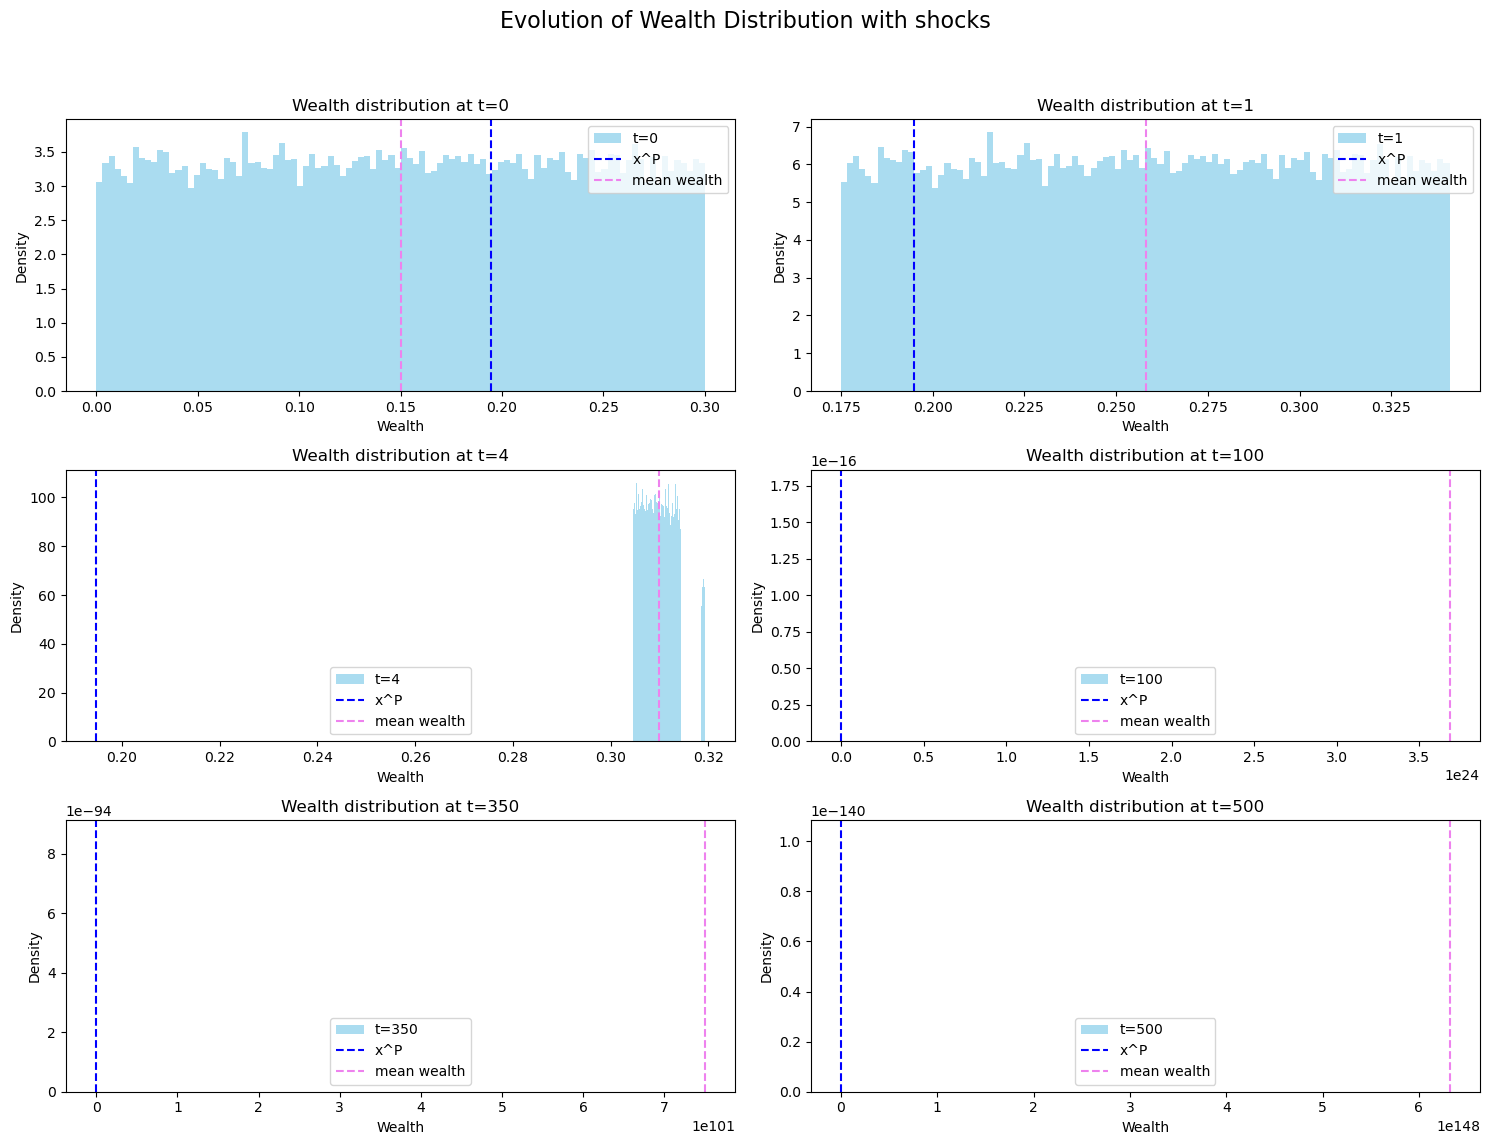

In [ ]:
T=500
yhigh=0.3
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_shock(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
meanwealth= np.mean(history[T])

print('mean final wealth =', meanwealth)
print('n_p_final=', n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 4, 100, 350, 500]):
    t = t_val
    ax = axes[i]
    mean=np.mean(history[t])
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    #ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(mu, r, alpha, A_up_bar, Ybar), color='blue', linestyle='--', label="x^P")
    ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', mean)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with shocks', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

#### Fine tuning dei parametri s.t. a_L(xF)<xF, a_R(xF)<xF e che a_R(1) >1, aR(0)<1 e con shock tutto sotto => n_fin^P=1

In [ ]:
p = 0.5
gamma_p = 0.8
gamma_up = 0.9

A_up_bar = 1.1
A_p_bar = 1.1
F=1
xF= F/(1+mu)
n_p=0

print ('Condizione 35 expected ',Primacondizione(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 expected ',Secondacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) expected ',Terzacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) expected ',Quartacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 no shock ',Primacondizionenoshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 no shock ',Secondacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) no shock',Terzacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) no shock ',Quartacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 shock ',Primacondizioneshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 shock ',Secondacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar ))
print ('Condizione 37(np=0) shock',Terzacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) shock ', Quartacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))

Condizione 35 expected  True
Condizione 36 expected  False
Condizione 37(np=0) expected  True
Condizione 47(np=1) expected  True

Condizione 35 no shock  True
Condizione 36 no shock  False
Condizione 37(np=0) no shock True
Condizione 47(np=1) no shock  True

Condizione 35 shock  True
Condizione 36 shock  False
Condizione 37(np=0) shock True
Condizione 47(np=1) shock  False


Distribuzione con nP_in=0

n_p_initial= 0.0
mean final wealth = 1.7752030831231662e+151
n_p_final= 1.0
mean wealth at t= 0 :	 0.1496309768545629
mean wealth at t= 1 :	 0.1446249116985237
mean wealth at t= 4 :	 0.34974943759075244
mean wealth at t= 100 :	 8.215979203062759e+27
mean wealth at t= 350 :	 1.0565172051065887e+104
mean wealth at t= 500 :	 1.7752030831231662e+151


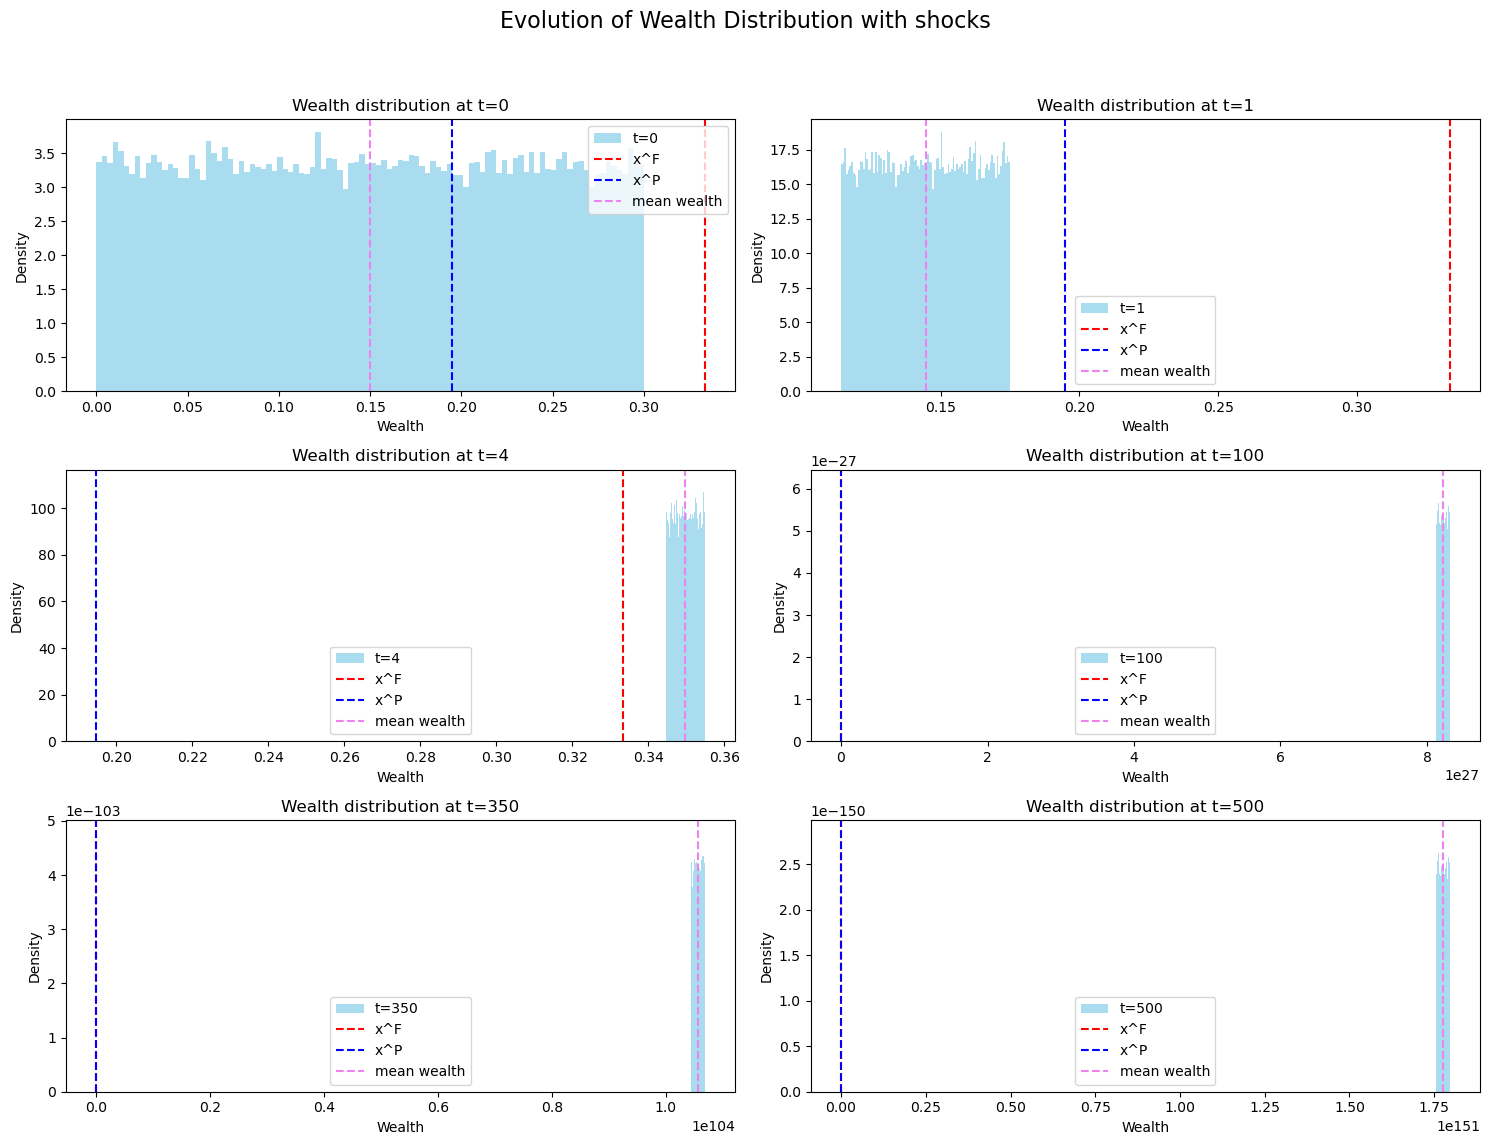

In [ ]:
T=500
yhigh=0.3
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_shock(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
meanwealth= np.mean(history[T])

print('mean final wealth =', meanwealth)
print('n_p_final=', n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 4, 100, 350, 500]):
    t = t_val
    ax = axes[i]
    mean=np.mean(history[t])
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(mu, r, alpha, A_up_bar, Ybar), color='blue', linestyle='--', label="x^P")
    ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', mean)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with shocks', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

#### Fine tuning dei parametri s.t. a_L(xF)<xF, a_R(xF)<xF e che a_R(1)_exp <1, aR(0)<1 e con shock tutto sotto => 

In [ ]:
p = 0.5
gamma_p = 0.8
gamma_up = 0.9

A_up_bar = 0.8
A_p_bar = 0.9
F=2
xF= F/(1+mu)
n_p=0

print ('Condizione 35 expected ',Primacondizione(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 expected ',Secondacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) expected ',Terzacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) expected ',Quartacondizione(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 no shock ',Primacondizionenoshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 no shock ',Secondacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 37(np=0) no shock',Terzacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) no shock ',Quartacondizionenoshock(mu, r, alpha, xF, A_p_bar, Ybar))
print('')
print ('Condizione 35 shock ',Primacondizioneshock(mu, r, alpha, xF, A_up_bar, Ybar))
print ('Condizione 36 shock ',Secondacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar ))
print ('Condizione 37(np=0) shock',Terzacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))
print ('Condizione 47(np=1) shock ', Quartacondizioneshock(mu, r, alpha, xF, A_p_bar, Ybar))

Condizione 35 expected  True
Condizione 36 expected  False
Condizione 37(np=0) expected  True
Condizione 47(np=1) expected  False

Condizione 35 no shock  True
Condizione 36 no shock  False
Condizione 37(np=0) no shock True
Condizione 47(np=1) no shock  True

Condizione 35 shock  True
Condizione 36 shock  False
Condizione 37(np=0) shock True
Condizione 47(np=1) shock  False


n_p_initial= 0.0
mean final wealth = 5.686671222213628e+150
n_p_final= 1.0
mean wealth at t= 0 :	 0.15045835024777965
mean wealth at t= 1 :	 0.14445695489970073
mean wealth at t= 4 :	 0.14547813088914424
mean wealth at t= 100 :	 2.6356058859682293e+21
mean wealth at t= 350 :	 2.6896794304623696e+101
mean wealth at t= 500 :	 5.686671222213628e+150


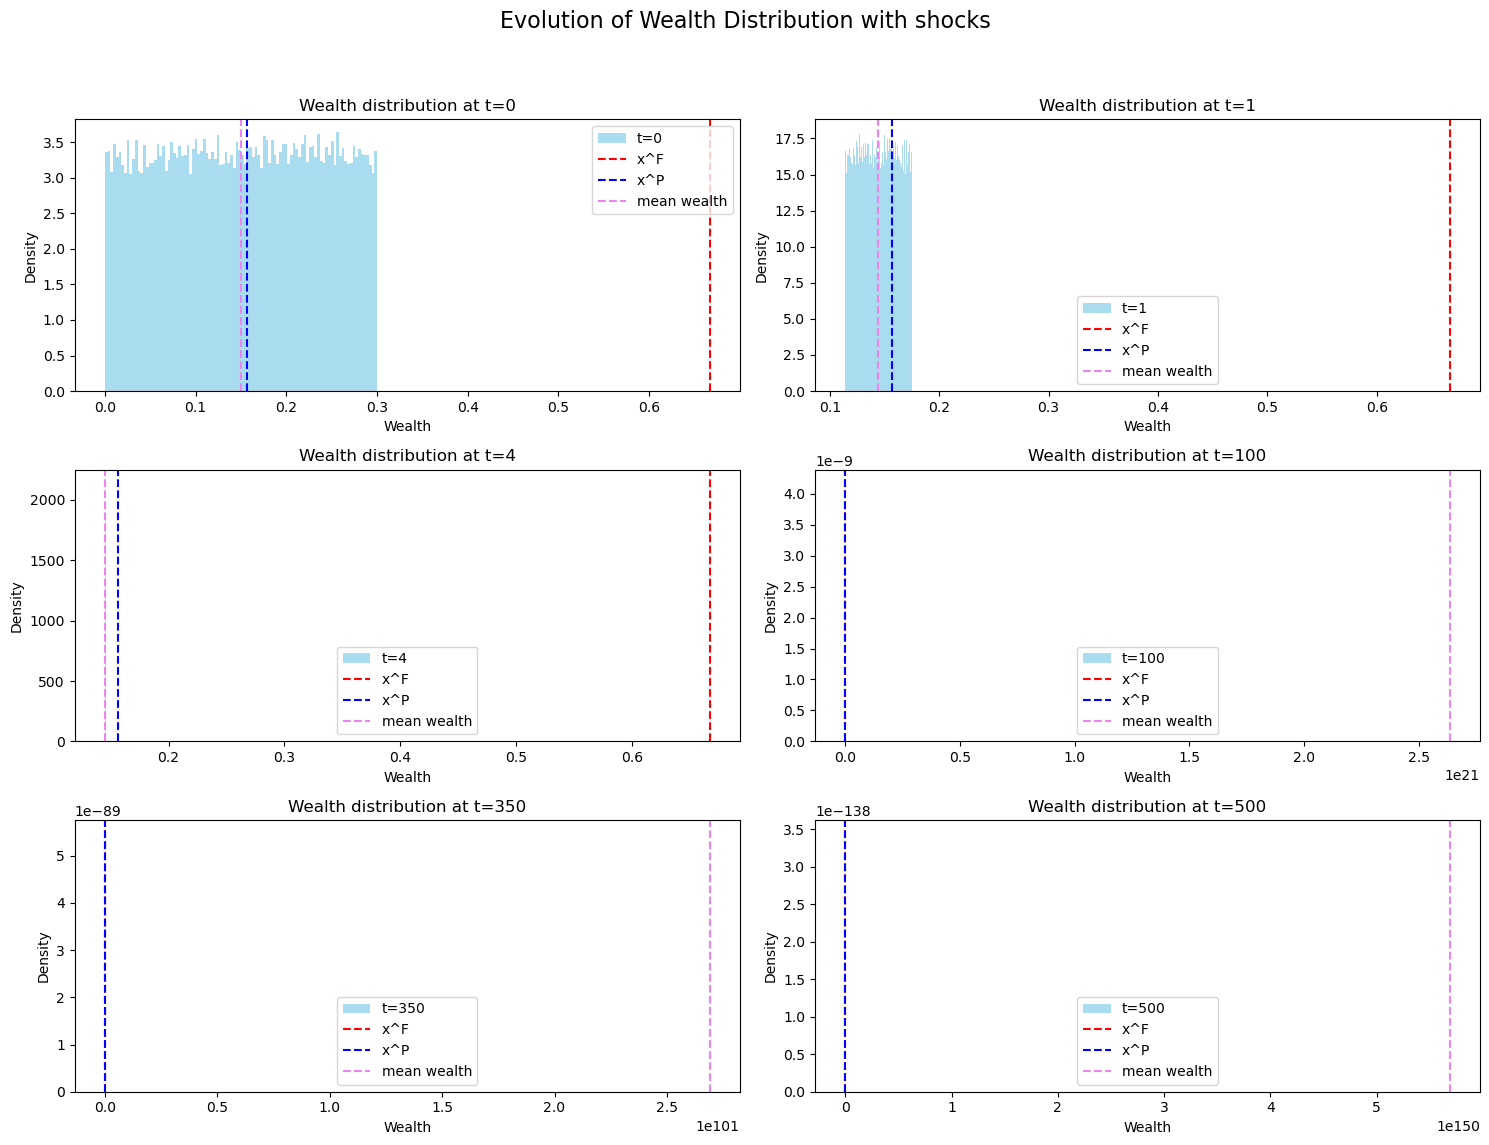

In [ ]:
T=500
yhigh=0.3
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_shock(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
meanwealth= np.mean(history[T])

print('mean final wealth =', meanwealth)
print('n_p_final=', n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 4, 100, 350, 500]):
    t = t_val
    ax = axes[i]
    mean=np.mean(history[t])
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(mu, r, alpha, A_up_bar, Ybar), color='blue', linestyle='--', label="x^P")
    ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', mean)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with shocks', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

non funziona. dovrebbe essere che arrivano all attrattore ricco, no? se np iniziale è sotto n*